# PubMed Publication Trend Analysis

Publication trends in single-cell genomics and spatial transcriptomics, built on the NCBI E-utilities API.

This notebook:

1. Counts PubMed papers per year (2015-2025) for three biomedical topics.
2. Downloads a sample of abstracts for single-cell brain research (2019-2025) and parses them into a table.
3. Measures how often selected disease keywords appear in those abstracts, by year.
4. Writes the tables to CSV and the charts to PNG.

**Data source:** PubMed, via the [NCBI E-utilities](https://www.ncbi.nlm.nih.gov/books/NBK25497/).
**Stack:** Python, Requests, Pandas, Matplotlib.

**Usage:** set the `NCBI_EMAIL` environment variable (or edit `CONTACT_EMAIL` below), then run all cells from top to bottom. NCBI asks API users to identify themselves.

## 1. Setup

In [ ]:
!pip install -q requests pandas matplotlib

In [ ]:
import os
import re
import time
import xml.etree.ElementTree as ET

import requests
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

## 2. Configuration

Queries use the `[tiab]` field tag, which restricts matching to title and abstract.

In [ ]:
BASE_URL = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/"
CONTACT_EMAIL = os.environ.get("NCBI_EMAIL", "adrspande10@gmail.com")
TOOL_NAME = "pubmed_trend_analysis"

TOPICS = {
    "Single-cell genomics": '"single-cell"[tiab] AND (genomics[tiab] OR "RNA-seq"[tiab] OR transcriptomics[tiab])',
    "Spatial transcriptomics": '"spatial transcriptomics"[tiab]',
    "Single-cell + brain": '"single-cell"[tiab] AND (brain[tiab] OR neuro*[tiab])',
}

COUNT_YEARS = range(2015, 2026)
ABSTRACT_TOPIC = "Single-cell + brain"
ABSTRACT_YEARS = range(2019, 2026)
ABSTRACTS_PER_YEAR = 40

KEYWORDS = ["alzheimer", "parkinson", "autism", "schizophrenia", "covid", "tuberculosis", "hiv", "malaria"]

## 3. API client

All requests go through one function that adds the identification parameters, raises on HTTP errors, and pauses 0.4 s afterwards to stay under NCBI's limit of about 3 requests per second without an API key.

In [ ]:
def call_ncbi(endpoint, params):
    """Send a GET request to an E-utilities endpoint and return the response."""
    params = dict(params)
    params["tool"] = TOOL_NAME
    params["email"] = CONTACT_EMAIL
    response = requests.get(BASE_URL + endpoint, params=params, timeout=30)
    response.raise_for_status()
    time.sleep(0.4)
    return response

## 4. Publication counts per year

`esearch` with `retmax=0` returns only the total number of matches, so each year costs one lightweight request.

In [ ]:
def count_per_year(query, years):
    """Return {year: number of PubMed records} for a query."""
    counts = {}
    for year in years:
        response = call_ncbi("esearch.fcgi", {
            "db": "pubmed",
            "term": query,
            "datetype": "pdat",
            "mindate": year,
            "maxdate": year,
            "retmax": 0,
            "retmode": "json",
        })
        counts[year] = int(response.json()["esearchresult"]["count"])
    return counts

## 5. Abstract collection and parsing

- `find_ids` retrieves PubMed IDs (PMIDs) for one year, ranked by relevance.
- `fetch_xml` downloads the full records for those IDs.
- `parse_articles` extracts PMID, year, title and abstract from the XML, handling `MedlineDate` values such as "2020 Jan-Feb".
- `download_abstracts` runs the three steps for each year and returns a cleaned DataFrame.

In [ ]:
def find_ids(query, year, how_many):
    """Return up to `how_many` PMIDs for records published in `year`."""
    response = call_ncbi("esearch.fcgi", {
        "db": "pubmed",
        "term": query,
        "datetype": "pdat",
        "mindate": year,
        "maxdate": year,
        "retmax": how_many,
        "sort": "relevance",
        "retmode": "json",
    })
    return response.json()["esearchresult"]["idlist"]


def fetch_xml(pmids):
    """Download full PubMed records for a list of PMIDs as an XML string."""
    response = call_ncbi("efetch.fcgi", {
        "db": "pubmed",
        "id": ",".join(pmids),
        "retmode": "xml",
    })
    return response.text


def get_text(element):
    """Return all text inside an XML element, including nested tags."""
    if element is None:
        return ""
    return "".join(element.itertext()).strip()


def parse_articles(xml_text):
    """Parse PubMed XML into a list of dicts with pmid, year, title and abstract."""
    root = ET.fromstring(xml_text)
    rows = []
    for article in root.findall(".//PubmedArticle"):
        pmid = article.findtext(".//PMID")
        title = get_text(article.find(".//ArticleTitle"))
        abstract_parts = article.findall(".//Abstract/AbstractText")
        abstract = " ".join(get_text(p) for p in abstract_parts)
        year = article.findtext(".//JournalIssue/PubDate/Year")
        if year is None:
            medline_date = article.findtext(".//JournalIssue/PubDate/MedlineDate") or ""
            match = re.search(r"\d{4}", medline_date)
            year = match.group(0) if match else None
        rows.append({"pmid": pmid, "year": year, "title": title, "abstract": abstract})
    return rows


def download_abstracts(query, years, per_year):
    """Collect a yearly sample of abstracts into one cleaned DataFrame."""
    all_rows = []
    for year in years:
        pmids = find_ids(query, year, per_year)
        if not pmids:
            continue
        all_rows.extend(parse_articles(fetch_xml(pmids)))
    df = pd.DataFrame(all_rows)
    df = df.dropna(subset=["year"])
    df = df[df["abstract"].str.len() > 0]
    df["year"] = df["year"].astype(int)
    return df

## 6. Keyword frequency

Each abstract is lowercased and tested against every keyword with a word-start regular expression, so `hiv` matches "HIV-1" but not "archive". The mean of the resulting booleans per year, times 100, is the percentage of sampled abstracts mentioning the term.

In [ ]:
def keyword_share_by_year(df, keywords):
    """Return the percentage of abstracts per year that mention each keyword."""
    text = df["abstract"].str.lower()
    result = pd.DataFrame({"year": df["year"]})
    for word in keywords:
        pattern = r"\b" + re.escape(word)
        result[word] = text.str.contains(pattern, regex=True)
    return result.groupby("year").mean() * 100

## 7. Plotting

In [ ]:
def plot_counts(counts_df, filename):
    """Plot papers per year, one line per topic, and save to `filename`."""
    ax = counts_df.plot(marker="o", figsize=(9, 5))
    ax.set_title("PubMed papers per year by topic")
    ax.set_xlabel("Publication year")
    ax.set_ylabel("Number of papers")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.close()


def plot_keywords(share_df, filename, topic_name):
    """Plot keyword percentages by year, save to `filename` and display it."""
    ax = share_df.plot(marker="o", figsize=(9, 5))
    ax.set_title("Disease keywords in abstracts: " + topic_name)
    ax.set_xlabel("Publication year")
    ax.set_ylabel("% of sampled abstracts mentioning the word")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()
    plt.close()

## 8. Results: papers per year

One request per topic per year (33 in total).

In [ ]:
counts = {}
for name, query in TOPICS.items():
    print("Counting papers per year:", name)
    counts[name] = count_per_year(query, COUNT_YEARS)

counts_df = pd.DataFrame(counts)
counts_df.index.name = "year"
counts_df.to_csv("papers_per_year.csv")
plot_counts(counts_df, "papers_per_year.png")
counts_df

Counting papers per year: Single-cell genomics
Counting papers per year: Spatial transcriptomics
Counting papers per year: Single-cell + brain


,Single-cell genomics,Spatial transcriptomics,Single-cell + brain
year,,,
2015,170,2,338
2016,251,2,372
2017,390,5,475
2018,569,14,567
2019,805,22,635
2020,1225,71,861
2021,1879,162,1174
2022,2388,355,1398
2023,3026,716,1774


## 9. Results: abstract sample

In [ ]:
df = download_abstracts(TOPICS[ABSTRACT_TOPIC], ABSTRACT_YEARS, ABSTRACTS_PER_YEAR)
df.to_csv("abstracts_sample.csv", index=False)
print("Abstracts downloaded:", len(df))
df.head()

Abstracts downloaded: 280


,pmid,year,title,abstract
0,31042697,2019,Single-cell transcriptomic analysis of Alzheim...,Alzheimer's disease is a pervasive neurodegene...
1,30471926,2019,Single-Cell RNA Sequencing of Microglia throug...,"Microglia, the resident immune cells of the br..."
2,31585077,2019,Microglia Biology: One Century of Evolving Con...,Microglia were first recognized as a distinct ...
3,31422865,2019,CRISPR Interference-Based Platform for Multimo...,CRISPR/Cas9-based functional genomics have tra...
4,31097668,2019,Single-cell genomics identifies cell type-spec...,Despite the clinical and genetic heterogeneity...


## 10. Results: disease keywords by year

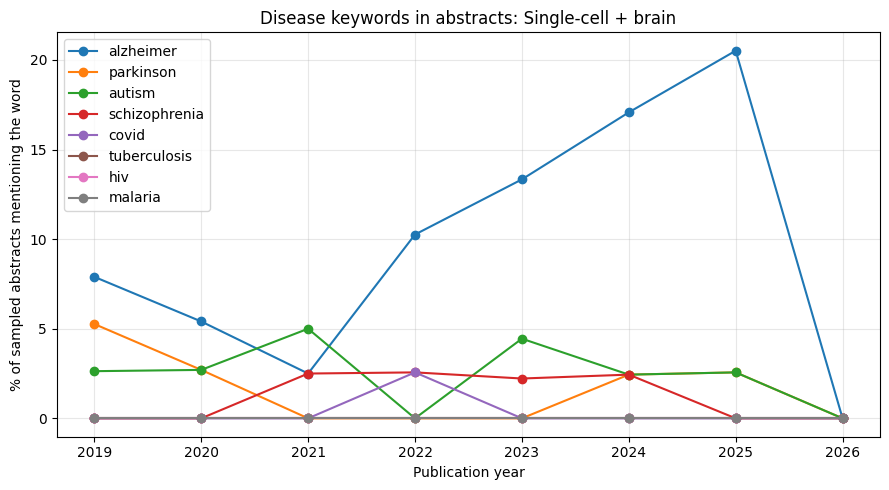

,alzheimer,parkinson,autism,schizophrenia,covid,tuberculosis,hiv,malaria
year,,,,,,,,
2019,7.9,5.3,2.6,0.0,0.0,0.0,0.0,0.0
2020,5.4,2.7,2.7,0.0,0.0,0.0,0.0,0.0
2021,2.5,0.0,5.0,2.5,0.0,0.0,0.0,0.0
2022,10.3,0.0,0.0,2.6,2.6,0.0,0.0,0.0
2023,13.3,0.0,4.4,2.2,0.0,0.0,0.0,0.0
2024,17.1,2.4,2.4,2.4,0.0,0.0,0.0,0.0
2025,20.5,2.6,2.6,0.0,0.0,0.0,0.0,0.0
2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
share_df = keyword_share_by_year(df, KEYWORDS)
share_df.to_csv("keyword_share_by_year.csv")
plot_keywords(share_df, "keywords_by_year.png", ABSTRACT_TOPIC)
share_df.round(1)

## 11. Observations

- All three topics grow every year from 2015 to 2025. Spatial transcriptomics grows fastest in relative terms, from 2 papers in 2015 to 2,444 in 2025; single-cell genomics reaches 5,614.
- Among the 280 sampled single-cell brain abstracts, Alzheimer's disease is the most frequently mentioned keyword (7.9% of 2019 abstracts, rising to about 20% in 2025). Parkinson's, autism and schizophrenia appear at low and uneven rates; tuberculosis, HIV and malaria do not appear.

## 12. Limitations

- The abstract sample is small (up to 40 per year, ranked by relevance), so keyword percentages are rough indicators, and single-year changes of a few points reflect only one or two abstracts.
- Keyword matching is plain text matching and ignores context such as negation.
- The year of each record is read from the journal issue date, which can differ from the publication-date filter used in the search. A few records therefore fall outside the requested range (a 2026 row appears in the keyword table).
- Counts depend on exact query wording and on indexing delays for recent papers. Only title and abstract are searched.

## 13. Possible extensions

- Add topics and diseases, and normalize counts by total PubMed output per year.
- Use an NCBI API key for a higher request rate.
- Replace keyword matching with biomedical named-entity recognition.